In [ ]:
import os
import warnings
from dataclasses import replace
from pathlib import Path
from tempfile import TemporaryDirectory

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np
import optuna

import pyrite

optuna.logging.set_verbosity(optuna.logging.WARNING)
with mo.status.spinner(title="Preparing PyRITE reference tables"):
    _ = pyrite.fetch_tables()
tables_ready = True
checkpoint_directory = TemporaryDirectory(prefix="pyrite-optimization-tutorial-")

# Optimizing an X-ray source

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/11-optimizing-xray-source.py)

Search graphite tilt (35–55°) and thickness (10–75 nm) for PXR/CBS yield
in **820–900 eV**, subject to a **50 nm** thickness limit. The 294-point
design space is larger than the 30-evaluation budget, so the optimizer must
choose where to look. Then evaluate the selected design with independent
seeds. The optimization API is experimental.

If run locally rather than on Molab, first install `Optuna` alongside `pyrite` with

```bash
uv tool install "pyrite-mc[optimization]"
```

In [ ]:
from pyrite import Scene
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab
from pyrite.optimization import (
    Constraint,
    FixedWindowYield,
    Integer,
    Objective,
    OptimizationStudy,
    OptunaOptimizer,
    ParameterSpace,
    PyriteEvaluator,
)
from pyrite.results import records
from pyrite.units import ureg

search_numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=16, brem_electrons=16),
    transport_core="per-electron",
    energy_bins=(
        EnergyBins()
        .with_cxr_energies(np.linspace(750, 1_000, 126) * ureg.eV)
        .with_brem_energies(np.array([750.0, 1_000.0]) * ureg.eV)
    ),
    cxr_reflections=CxrReflections(n_families=1),
)
base = Scene(
    Beam(kinetic_energy=30 * ureg.keV, transverse=PointSpot(), longitudinal=PointBunch()),
    Slab(
        "hopg",
        thickness=50 * ureg.nm,
        tilt=45 * ureg.degree,
        tilt_azimuth=180 * ureg.degree,
        footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
        mosaic=False,
    ),
    Detector(observation_angle=90 * ureg.degree),
    physics=Physics(
        brem_source=None,
        inelastic_model="continuous",
        radiative_model="uncoupled",
        bremsstrahlung_model="eedl",
    ),
    numerics=search_numerics,
)
score = FixedWindowYield(820 * ureg.eV, 900 * ureg.eV)
definition = OptimizationStudy(
    base,
    ParameterSpace(
        {
            "target.tilt": Integer(35 * ureg.degree, 55 * ureg.degree, step=1),
            "target.thickness": Integer(100 * ureg.angstrom, 750 * ureg.angstrom, step=50),
        }
    ),
    (Objective(score.name, "maximize", score.units),),
    (Constraint("thickness_ang", "<=", 500, "angstrom"),),
)

In [ ]:
def candidate_metrics(store):
    return {**score(store), "thickness_ang": records(store)[0]["case"]["thickness_ang"]}

In [ ]:
assert tables_ready
run_options = {
    "checkpoint_path": str(Path(checkpoint_directory.name) / "search.h5"),
    "max_workers": 0,
    "cache_read": False,
    "cache_write": False,
}
evaluator = PyriteEvaluator(candidate_metrics, base_seed=21, run_options=run_options)
with warnings.catch_warnings(action="ignore", category=optuna.exceptions.ExperimentalWarning):
    optimizer = OptunaOptimizer(
        definition.parameters,
        definition.objectives,
        constraints=definition.constraints,
        seed=21,
    )
with mo.status.spinner(
    title="Searching X-ray source designs",
    subtitle="Up to 30 evaluations (internal progress not available)",
):
    with mo.capture_stdout():
        search_result = definition.run(evaluator, optimizer, max_trials=30)
assert len(search_result.trials) == 30
assert all(_trial.state.value != "failed" for _trial in search_result.trials)
finalist = search_result.best_trial
assert finalist is not None

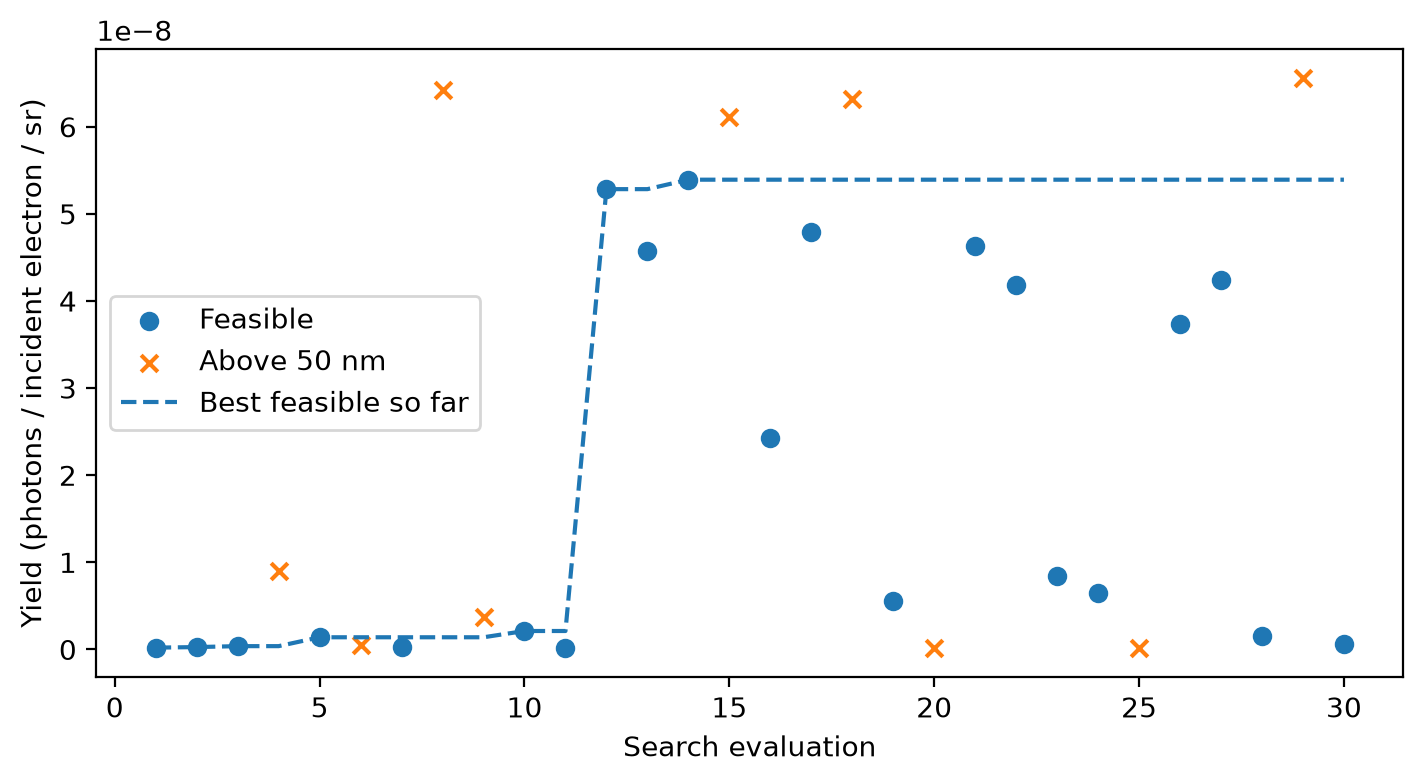

In [ ]:
fig_search, _ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
_trials = search_result.trials
_numbers = np.array([_trial.number + 1 for _trial in _trials])
_yields = np.array([_trial.objectives[score.name] for _trial in _trials])
_feasible = np.array([_trial.state.value == "completed" for _trial in _trials])
_ax.scatter(_numbers[_feasible], _yields[_feasible], label="Feasible")
_ax.scatter(_numbers[~_feasible], _yields[~_feasible], marker="x", label="Above 50 nm")
_best = np.maximum.accumulate(np.where(_feasible, _yields, -np.inf))
_best[_best == -np.inf] = np.nan
_ax.plot(_numbers, _best, "--", label="Best feasible so far")
_ax.set(
    xlabel="Search evaluation",
    ylabel="Yield (photons / incident electron / sr)",
)
_ax.legend()
fig_search  # noqa: B018

In [ ]:
assert tables_ready
validation_numerics = Numerics(
    transport_core="per-electron",
    cxr_reflections=search_numerics.cxr_reflections,
    sampling=FixedSampling(cxr_electrons=128, brem_electrons=128),
    energy_bins=(
        EnergyBins()
        .with_cxr_energies(np.linspace(750, 1_000, 251) * ureg.eV)
        .with_brem_energies(np.array([750.0, 1_000.0]) * ureg.eV)
    ),
)
validation_scene = replace(
    definition.scene(finalist.parameters),
    numerics=validation_numerics,
    physics=base.physics,
)
validation_evaluator = PyriteEvaluator(
    candidate_metrics,
    base_seed=1_001,
    run_options={
        **run_options,
        "checkpoint_path": run_options["checkpoint_path"].replace("search.h5", "validation.h5"),
    },
)
_independent = []
with mo.status.progress_bar(total=3, title="Validating the winning design") as _progress:
    with mo.capture_stdout():
        for _replicate in range(3):
            _independent.append(
                validation_evaluator(validation_scene, _replicate)[definition.objectives[0].name]
            )
            _progress.update(subtitle=f"Independent seed {_replicate + 1}/3")
independent_yields = np.array(_independent)
assert np.isfinite(independent_yields).all() and np.all(independent_yields >= 0)

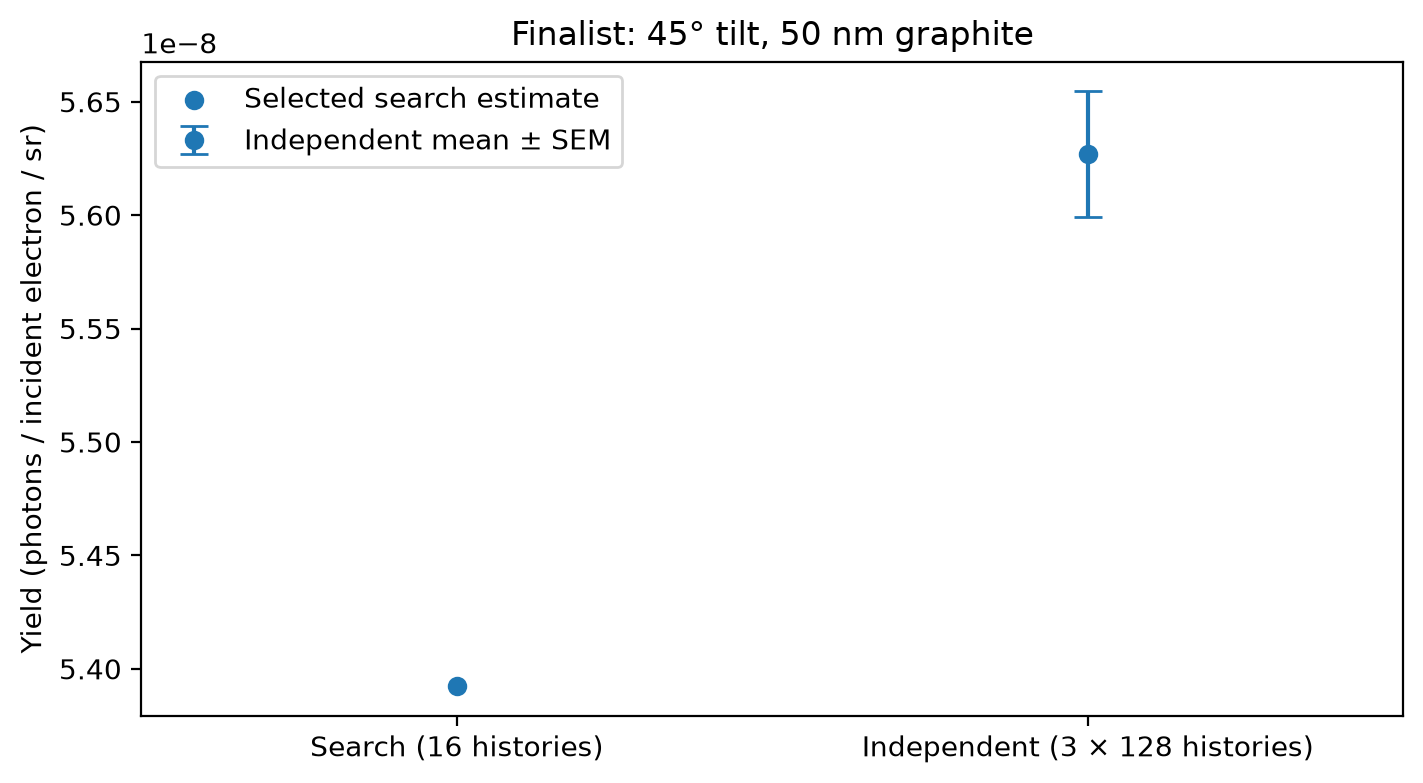

In [ ]:
fig_validation, _ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
_ax.scatter(0, finalist.objectives[score.name], label="Selected search estimate")
_ax.errorbar(
    1,
    independent_yields.mean(),
    yerr=independent_yields.std(ddof=1) / np.sqrt(3),
    fmt="o",
    capsize=5,
    label="Independent mean ± SEM",
)
_ax.set(
    xticks=(0, 1),
    xticklabels=("Search (16 histories)", "Independent (3 × 128 histories)"),
    ylabel="Yield (photons / incident electron / sr)",
    xlim=(-0.5, 1.5),
    title=f"Finalist: {finalist.parameters['target.tilt']:g}° tilt, "
    f"{finalist.parameters['target.thickness'] / 10:g} nm graphite",
)
_ax.legend()
fig_validation  # noqa: B018

The objective integrates the incoherent PXR/CBS source density at **90°**,
before detector response or angular acceptance. The physical beam energy
and material model stay fixed while the optimizer selects geometry.

Thirty search evaluations use 16 histories per population and seeds 21–50.
Optuna's TPE sampler draws its first ten proposals at random, then
concentrates later proposals near the best feasible designs. Thicknesses
above the constraint are evaluated but can never be selected.

**Report the independent estimate, not the search value.** Picking the best
of many noisy evaluations biases the search value upward (the "winner's
curse"); the bias matters when competing designs differ by less than the
per-evaluation noise. Here the designs differ by much more than the
16-history noise, so that bias is small, and the gap between the two points
mostly reflects sampling noise and the change from a **2 eV** to a **1 eV**
grid. The re-evaluation uses three new seeds, 1,001–1,003, and 128 histories;
its error bar describes sampling only, not grid or model uncertainty.

Try tightening the thickness constraint or narrowing the tilt range so the
candidates become similar, then compare the search and independent values
again. A selected maximum does not establish a global optimum.

## Continue learning

See the [optimization study reference](../../reference/optimization-studies.md)
for parameter, constraint and resume contracts; the
[optimization how-to](../../guides/optimization-studies.md) runs a larger comparison.
[Fixed-window integral evidence](../../validation/radiation-physics/optimization-fixed-window-yield.md)
checks the source-yield objective.

{download}`Download canonical Marimo notebook <../11-optimizing-xray-source.py>`